# 포르투갈 은행 텔레마케팅: 정기예금 가입 예측 (최종 코드)

- `banking project_1.ipynb` (Round 2)와 `banking project_1 - Copy.ipynb` (Round 3)의 코드를 하나로 합쳤습니다. **코드와 출력은 원본 그대로**입니다.
- 뺀 셀: 중단된 중복 셀, 실행하지 않은 중복 셀, 잠긴 옛 테스트 셀 (오류 출력), 전부 주석인 옛 교차검증 셀 (Step 1 셀로 대체됨).
- 읽기 쉽게 탐색 셀 몇 개 (데이터 미리보기, 상대빈도 그래프, 연결 데이터 보기)의 위치만 옮겼습니다. 이 셀들은 데이터를 읽기만 하고 바꾸지 않습니다.
- 두 노트북에서 실행한 셀이 섞여 있어 실행 번호는 지웠습니다. 두 노트북에 모두 있는 셀은 출력 숫자가 같습니다.
- Round 1 (80/20 분할) 결과는 `banking_project_1_organized_v3.ipynb`에 있습니다. 라벨 (A1–D2, ①②③)은 README와 같습니다.

| 구간 | 내용 |
|---|---|
| 1–3 | 데이터 불러오기, `unknown`·특수값 확인, 상대빈도 그래프 |
| 4–8 | 60/20/20 분할, 결측 대체, `duration` 제거, 대체 규칙의 통계적 근거, 원-핫 인코딩 |
| 9 | 기준선과 최종 설정 (train CV) |
| 10 | Round 2: A1–A3, B1–B3, C1, D1–D2, 테스트 |
| 11 | Round 3: 경제 지표 연결, 검증 ①②③, 테스트 (최종 모델) |

## 1. 데이터 불러오기와 구조 확인

In [ ]:
import pandas as pd

# quotechar='"' 추가하여 따옴표 제거 및 구분자 지정
df = pd.read_csv(r'C:\personal_project_1\bank\bank-full.csv', sep=';', quotechar='"')



df_clean = df


In [ ]:
def diagnose_structure(df_clean):
    with pd.option_context('display.max_rows', None, 'display.max_columns', None, 'display.width', 200):
      print("=" * 60)
      print("STEP 1. 구조 진단")
      print("=" * 60)
      print(f"\n[크기] (행, 열): {df_clean.shape}")
      print(f"\n[컬럼] {list(df_clean.columns)}")
      print(f"\n[자료형]\n{df_clean.dtypes}")
      print(f"\n[기초 통계량]\n{df_clean.describe()}")
      print(f"\n[컬럼별 결측치]\n{df_clean.isnull().sum()}")
      print(f"\n[완전 중복 행 개수] {df_clean.duplicated().sum()}")
      

diagnose_structure(df_clean)


STEP 1. 구조 진단

[크기] (행, 열): (45211, 17)

[컬럼] ['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'y']

[자료형]
age          int64
job            str
marital        str
education      str
default        str
balance      int64
housing        str
loan           str
contact        str
day          int64
month          str
duration     int64
campaign     int64
pdays        int64
previous     int64
poutcome       str
y              str
dtype: object

[기초 통계량]
                age        balance           day      duration      campaign         pdays      previous
count  45211.000000   45211.000000  45211.000000  45211.000000  45211.000000  45211.000000  45211.000000
mean      40.936210    1362.272058     15.806419    258.163080      2.763841     40.197828      0.580323
std       10.618762    3044.765829      8.322476    257.527812      3.098021    100.128746      2.303441
min       1

In [ ]:
df_clean.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [ ]:
df_clean['job'].value_counts()

job
blue-collar      9732
management       9458
technician       7597
admin.           5171
services         4154
retired          2264
self-employed    1579
entrepreneur     1487
unemployed       1303
housemaid        1240
student           938
unknown           288
Name: count, dtype: int64

## 2. `unknown`과 특수값 확인

In [ ]:
cat_cols=['job', 'education']

 ## 각 컬럼들이 여기에다가 들어오게끔 해야함



def diagnose_categorical(df_clean, cat_cols):
    print("=" * 60)
    print("STEP 2. 범주형 값 진단")
    print("=" * 60)
    for col in cat_cols:
        print(f"\n=== {col} (고유값 {df_clean[col].nunique(dropna=False)}개) ===")
        for val, cnt in df_clean[col].value_counts(dropna=False).items():
            print(f"  [{val!r}] : {cnt}")   # !r → 공백/따옴표까지 표시
            
            
diagnose_categorical(df_clean, cat_cols)


STEP 2. 범주형 값 진단

=== job (고유값 12개) ===
  ['blue-collar'] : 9732
  ['management'] : 9458
  ['technician'] : 7597
  ['admin.'] : 5171
  ['services'] : 4154
  ['retired'] : 2264
  ['self-employed'] : 1579
  ['entrepreneur'] : 1487
  ['unemployed'] : 1303
  ['housemaid'] : 1240
  ['student'] : 938
  ['unknown'] : 288

=== education (고유값 4개) ===
  ['secondary'] : 23202
  ['tertiary'] : 13301
  ['primary'] : 6851
  ['unknown'] : 1857


In [ ]:
a = df_clean[(df_clean['education'] == 'unknown')]
a 

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no
13,58,technician,married,unknown,no,71,yes,no,unknown,5,may,71,1,-1,0,unknown,no
16,45,admin.,single,unknown,no,13,yes,no,unknown,5,may,98,1,-1,0,unknown,no
42,60,blue-collar,married,unknown,no,104,yes,no,unknown,5,may,22,1,-1,0,unknown,no
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
45129,46,technician,married,unknown,no,3308,no,no,cellular,27,oct,171,1,91,2,success,yes
45141,77,unknown,married,unknown,no,397,no,no,telephone,8,nov,207,1,185,3,success,no
45150,65,management,married,unknown,no,2352,no,no,cellular,8,nov,354,3,188,13,success,no
45158,34,student,single,unknown,no,2321,no,no,cellular,9,nov,600,2,99,5,failure,no


In [ ]:
print(df_clean['pdays'].value_counts())


pdays
-1      36954
 182      167
 92       147
 91       126
 183      126
        ...  
 541        1
 543        1
 871        1
 550        1
 530        1
Name: count, Length: 559, dtype: int64


`poutcome = unknown`은 `pdays = -1` (이전 연락 없음)과 거의 일치하고, `contact = unknown`은 5–6월에 몰려 있습니다.

In [ ]:
pd.crosstab(df["poutcome"], df["pdays"] == -1)

pdays,False,True
poutcome,,
failure,4901,0
other,1840,0
success,1511,0
unknown,5,36954


In [ ]:
pd.crosstab(df["month"], df["contact"] == "unknown")

contact,False,True
month,,
apr,2926,6
aug,6196,51
dec,211,3
feb,2636,13
jan,1394,9
jul,6619,276
jun,809,4532
mar,470,7
may,5791,7975


## 3. 상대빈도 그래프 (Y. Dong 2024, Sec. 2)
원본 데이터 (`duration` 제외, 대체 전).

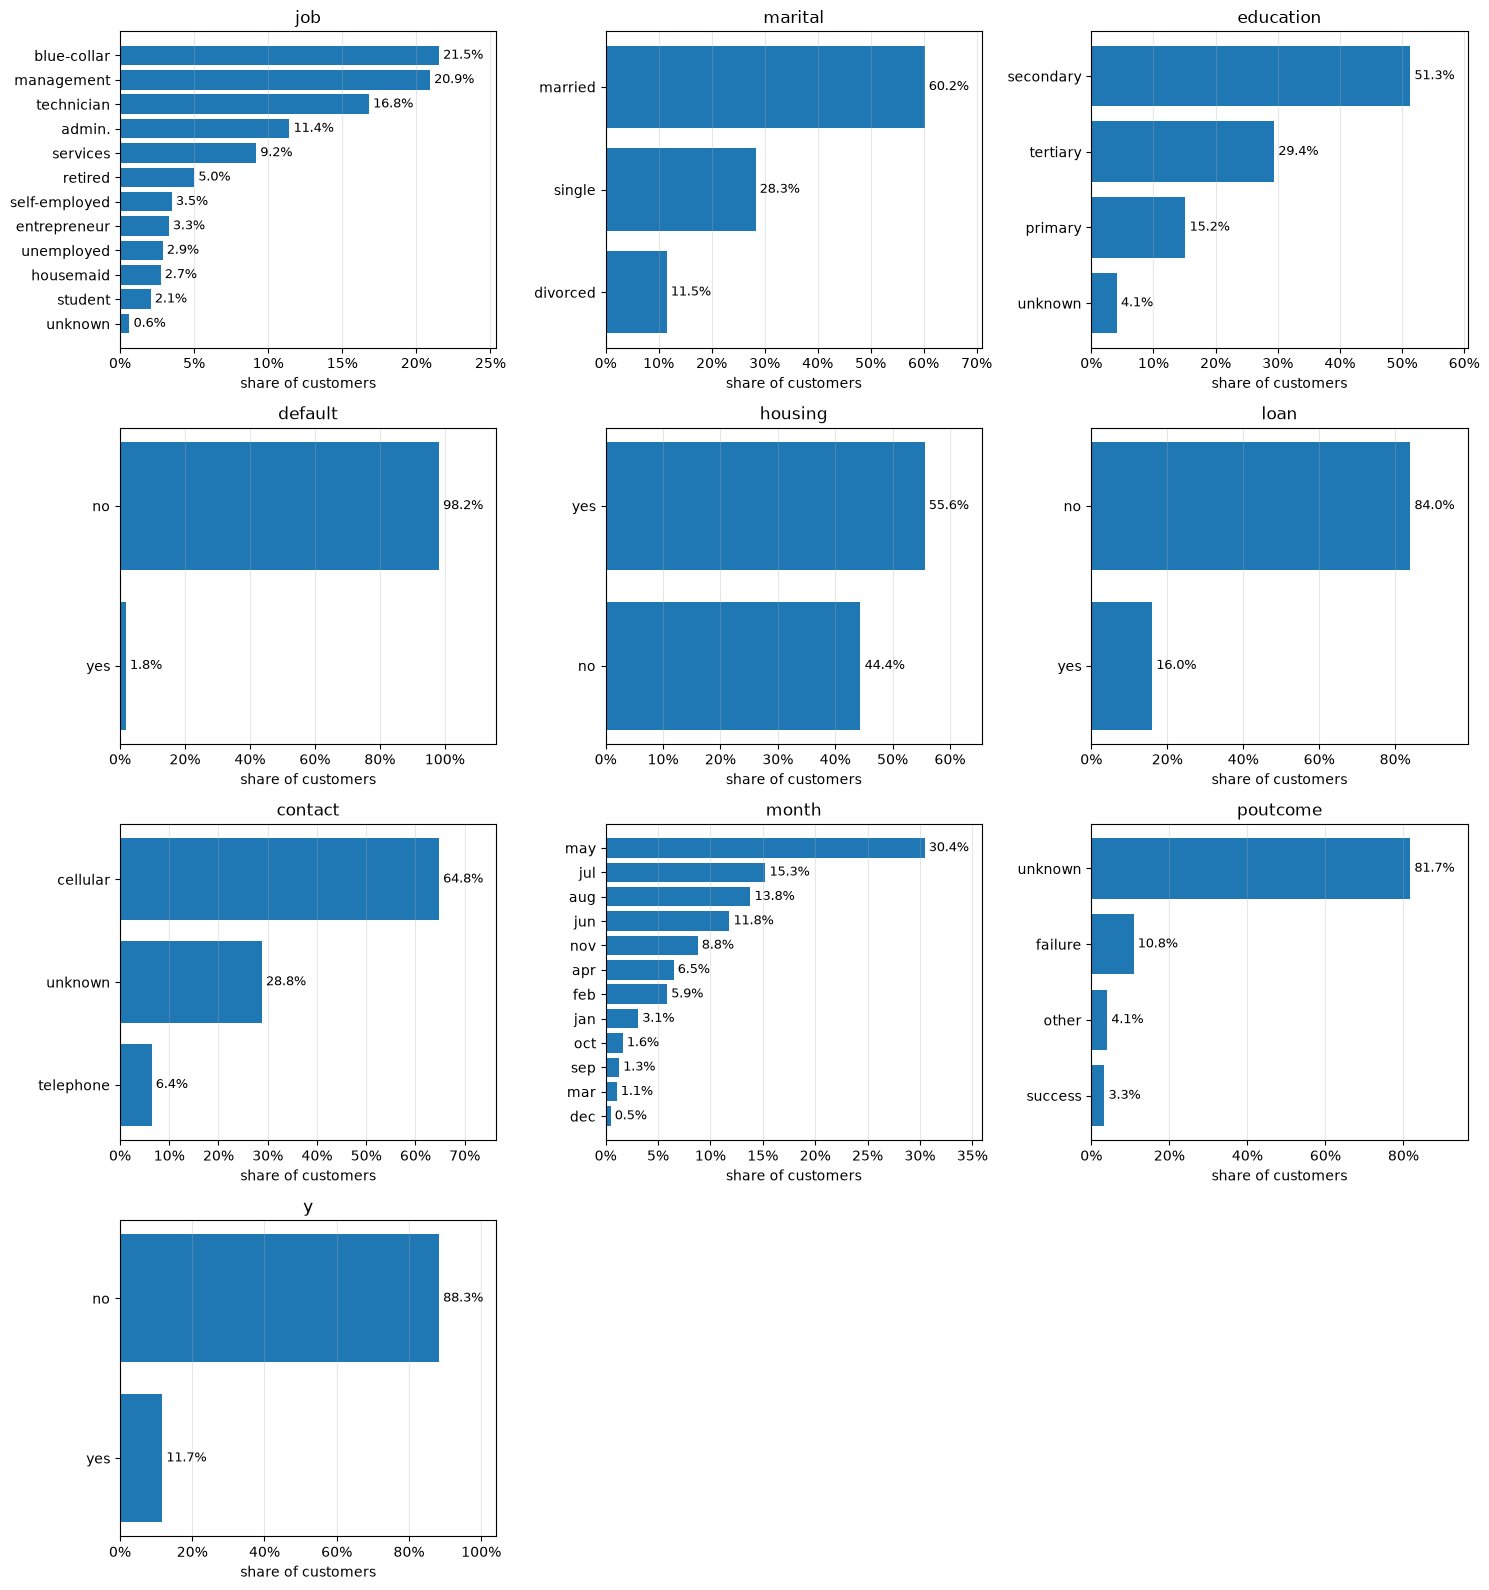

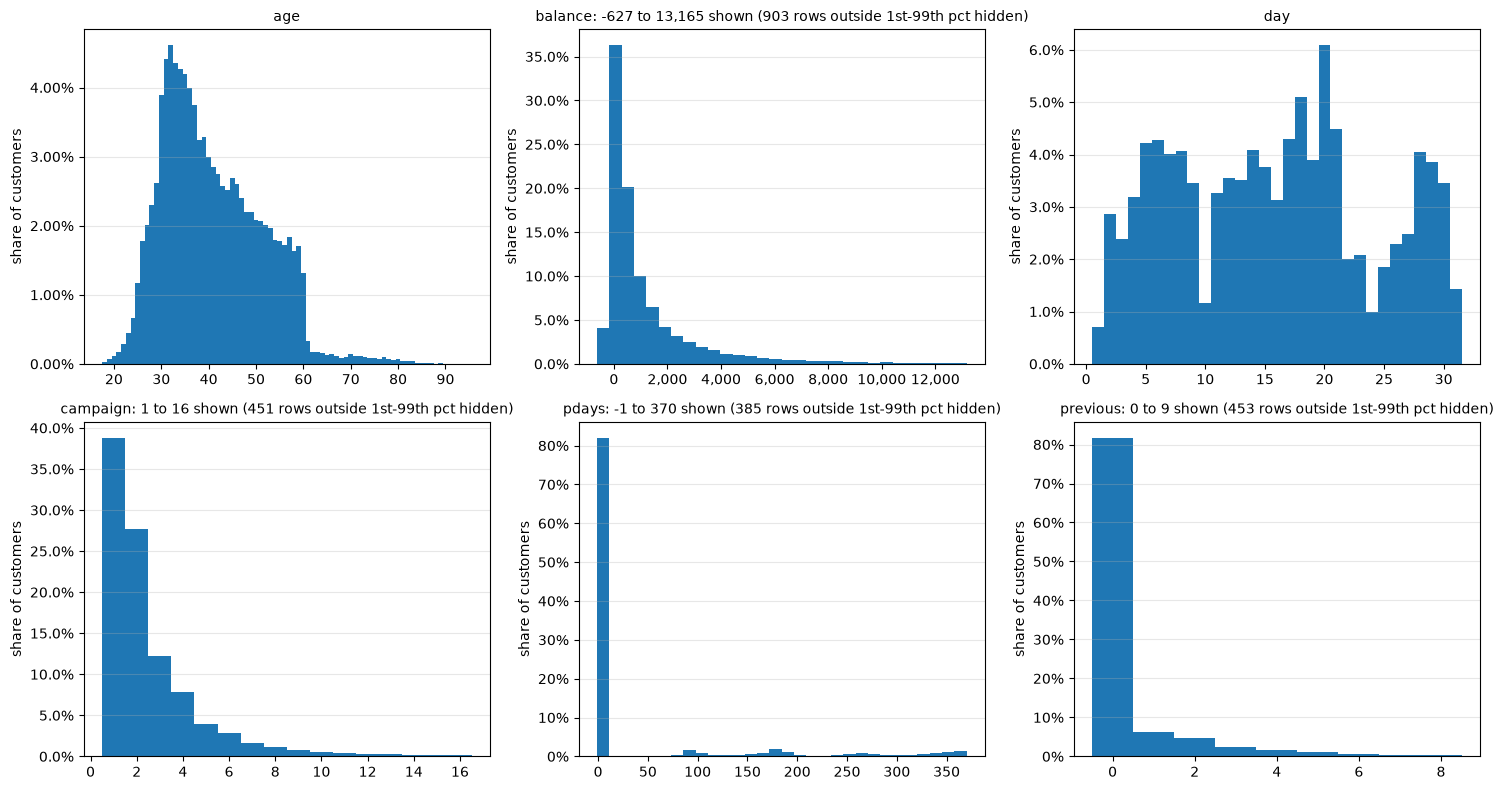

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter, StrMethodFormatter

data = df.drop(columns="duration")   # original data, before imputation

# Own names, so this cell never overwrites cat_cols / num_cols used by the models
plot_cat_cols = ["job", "marital", "education", "default", "housing", "loan",
                 "contact", "month", "poutcome", "y"]
plot_num_cols = ["age", "balance", "day", "campaign", "pdays", "previous"]
skewed = ["balance", "campaign", "pdays", "previous"]   # long tails: show the 1st-99th percentile range

# Categorical: share of customers in each category, with the % written on each bar
fig, axes = plt.subplots(4, 3, figsize=(15, 16))
for ax, col in zip(axes.flat, plot_cat_cols):
    share = data[col].value_counts(normalize=True).sort_values()
    bars = ax.barh(share.index, share.values)
    ax.bar_label(bars, labels=[f"{v:.1%}" for v in share.values], padding=3, fontsize=9)
    ax.set_xlim(0, share.max() * 1.18)                       # room for the labels
    ax.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
    ax.grid(axis="x", alpha=0.3)
    ax.set_title(col)
    ax.set_xlabel("share of customers")
for ax in axes.flat[len(plot_cat_cols):]:
    ax.axis("off")                    # hide the 2 empty panels
plt.tight_layout()
plt.show()

# Numerical: histogram where each bar is a share of ALL customers
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, plot_num_cols):
    x = data[col]
    title = col
    if col in skewed:                                        # display only: the data is not changed
        lo, hi = x.quantile([0.01, 0.99])
        n_out = ((x < lo) | (x > hi)).sum()
        x = x[(x >= lo) & (x <= hi)]
        title = f"{col}: {lo:,.0f} to {hi:,.0f} shown ({n_out:,} rows outside 1st-99th pct hidden)"
    if x.max() - x.min() <= 100:                             # small whole numbers: one bar per value
        bins = np.arange(x.min(), x.max() + 2) - 0.5
    else:
        bins = 30
    ax.hist(x, bins=bins, weights=np.ones(len(x)) / len(data))
    ax.yaxis.set_major_formatter(PercentFormatter(1.0))
    ax.xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
    ax.grid(axis="y", alpha=0.3)
    ax.set_title(title, fontsize=10)
    ax.set_ylabel("share of customers")
plt.tight_layout()
plt.show()

## 4. 분할 (train 60% / validation 20% / test 20%)과 education 대체
대체 규칙은 train에서만 배우고 validation·test에는 적용만 합니다. 테스트는 `RUN_TEST = False`로 잠급니다.

In [ ]:
from sklearn.model_selection import train_test_split

# 1. Split: 60% train / 20% validation / 20% test
X = df.drop(columns="y")
y = (df["y"] == "yes").astype(int)
X_trainval, X_test, y_trainval, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)          # test = same 20% as before
X_train, X_val, y_train, y_val = train_test_split(
    X_trainval, y_trainval, test_size=0.25, stratify=y_trainval, random_state=42)   # 0.25 x 80% = 20%
RUN_TEST = False                                                 # test set locked until the final run

# 2. Learn: most common education for each job (training data only)
known = X_train[(X_train["job"] != "unknown") & (X_train["education"] != "unknown")]
job_to_edu = known.groupby("job")["education"].agg(lambda s: s.mode()[0])
print(job_to_edu)

# 3. Fill unknown education using the job
for data in [X_train, X_val, X_test]:
    mask = data["education"] == "unknown"
    data.loc[mask, "education"] = data.loc[mask, "job"].map(job_to_edu).fillna("unknown")

job
admin.           secondary
blue-collar      secondary
entrepreneur      tertiary
housemaid          primary
management        tertiary
retired          secondary
self-employed     tertiary
services         secondary
student          secondary
technician       secondary
unemployed       secondary
Name: education, dtype: str


## 5. job 대체 규칙 확인과 적용
규칙마다 train에서 "가장 흔한 범주가 맞는 비율"을 확인하고, 높은 규칙만 적용합니다.

In [ ]:
def check_rule(data, by, target):
    known = data[target] != "unknown"
    groups = by[known] if isinstance(by, pd.Series) else data.loc[known, by]
    return data.loc[known, target].groupby(groups).agg(
        guess=lambda s: s.mode()[0],
        accuracy=lambda s: round(s.value_counts(normalize=True).iloc[0], 2),
        n="size",
    )

In [ ]:
print("Education unknown -> train:", (X_train["education"] == "unknown").sum(),
      "| test:", (X_test["education"] == "unknown").sum())

Education unknown -> train: 73 | test: 24


In [ ]:
print(check_rule(X_train, "education", "job"))

                 guess  accuracy      n
education                              
primary    blue-collar      0.54   4109
secondary  blue-collar      0.24  14689
tertiary    management      0.59   8149


In [ ]:
age_group = pd.cut(X_train["age"], bins=[17, 29, 59, 100], labels=["18-29", "30-59", "60+"])
print(check_rule(X_train, age_group, "job"))

             guess  accuracy      n
age                                
18-29  blue-collar      0.22   3183
30-59  blue-collar      0.22  22698
60+        retired      0.62   1066


In [ ]:
for data in [X_train, X_val, X_test]:
    mask = (data["job"] == "unknown") & (data["age"] >= 60)
    data.loc[mask, "job"] = "retired"

In [ ]:
print(check_rule(X_train, "housing", "job"))
print(check_rule(X_train, "loan", "job"))

               guess  accuracy      n
housing                              
no        management      0.24  11833
yes      blue-collar      0.28  15131
            guess  accuracy      n
loan                              
no     management      0.22  22562
yes   blue-collar      0.23   4402


In [ ]:
edu_to_job = {"primary": "blue-collar", "tertiary": "management"}

for data in [X_train, X_val, X_test]:
    mask = (data["job"] == "unknown") & (data["education"].isin(edu_to_job))
    data.loc[mask, "job"] = data.loc[mask, "education"].map(edu_to_job)

In [ ]:
for col in ["job", "education"]:
    print(col, "-> train:", (X_train[col] == "unknown").sum(),
          "| test:", (X_test[col] == "unknown").sum())

job -> train: 106 | test: 34
education -> train: 73 | test: 24


In [ ]:
print(known.groupby("job")["education"].agg(lambda s: s.value_counts(normalize=True).iloc[0]).round(2))

job
admin.           0.85
blue-collar      0.58
entrepreneur     0.51
housemaid        0.54
management       0.85
retired          0.46
self-employed    0.56
services         0.87
student          0.66
technician       0.71
unemployed       0.58
Name: education, dtype: float64


## 6. `duration` 제거 (누수 방지, Y. Dong 2024 Sec. 2)와 정리된 데이터 확인

In [ ]:
X_train = X_train.drop(columns="duration")
X_val   = X_val.drop(columns="duration")
X_test  = X_test.drop(columns="duration")

print(X_train.shape, X_val.shape, X_test.shape)  # should be 15 columns each

(27126, 15) (9042, 15) (9043, 15)


In [ ]:
print("In train:", (X_train["previous"] == 275).sum(), "| In test:", (X_test["previous"] == 275).sum())

In train: 0 | In test: 0


In [ ]:
pd.set_option("display.max_columns", None)  # show every column

full_view = pd.concat([
    X_train.assign(y=y_train, set="train"),
    X_val.assign(y=y_val,     set="val"),
    X_test.assign(y=y_test,   set="test"),
]).sort_index()

print("Shape:", full_view.shape)
print(full_view.dtypes)
display(full_view.head(10))
display(full_view.describe())

print("\nRemaining 'unknown' per column:")
cat_cols = full_view.select_dtypes(exclude="number").columns.drop("set")
for col in cat_cols:
    n = (full_view[col] == "unknown").sum()
    if n > 0:
        print(f"  {col}: {n}")

Shape: (45211, 17)
age          int64
job            str
marital        str
education      str
default        str
balance      int64
housing        str
loan           str
contact        str
day          int64
month          str
campaign     int64
pdays        int64
previous     int64
poutcome       str
y            int64
set            str
dtype: object


,age,job,marital,education,default,balance,housing,loan,contact,day,month,campaign,pdays,previous,poutcome,y,set
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,1,-1,0,unknown,0,train
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,1,-1,0,unknown,0,train
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,1,-1,0,unknown,0,val
3,47,blue-collar,married,secondary,no,1506,yes,no,unknown,5,may,1,-1,0,unknown,0,val
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,1,-1,0,unknown,0,train
5,35,management,married,tertiary,no,231,yes,no,unknown,5,may,1,-1,0,unknown,0,train
6,28,management,single,tertiary,no,447,yes,yes,unknown,5,may,1,-1,0,unknown,0,train
7,42,entrepreneur,divorced,tertiary,yes,2,yes,no,unknown,5,may,1,-1,0,unknown,0,train
8,58,retired,married,primary,no,121,yes,no,unknown,5,may,1,-1,0,unknown,0,train
9,43,technician,single,secondary,no,593,yes,no,unknown,5,may,1,-1,0,unknown,0,test


,age,balance,day,campaign,pdays,previous,y
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,2.763841,40.197828,0.580323,0.116985
std,10.618762,3044.765829,8.322476,3.098021,100.128746,2.303441,0.321406
min,18.000000,-8019.000000,1.000000,1.000000,-1.000000,0.000000,0.000000
25%,33.000000,72.000000,8.000000,1.000000,-1.000000,0.000000,0.000000
50%,39.000000,448.000000,16.000000,2.000000,-1.000000,0.000000,0.000000
75%,48.000000,1428.000000,21.000000,3.000000,-1.000000,0.000000,0.000000
max,95.000000,102127.000000,31.000000,63.000000,871.000000,275.000000,1.000000



Remaining 'unknown' per column:
  job: 178
  education: 127
  contact: 13020
  poutcome: 36959


In [ ]:
print(full_view.groupby("poutcome")["y"].agg(["mean", "size"]).round(3))

           mean   size
poutcome              
failure   0.126   4901
other     0.167   1840
success   0.647   1511
unknown   0.092  36959


In [ ]:
result = pd.crosstab(full_view["job"], full_view["education"])
print(result)

education      primary  secondary  tertiary  unknown
job                                                 
admin.             209       4390       572        0
blue-collar       3807       5825       149        0
entrepreneur       183        542       762        0
housemaid          672        395       173        0
management         294       1121      8076        0
retired            797       1108       372       15
self-employed      130        577       872        0
services           345       3607       202        0
student             44        671       223        0
technician         158       5471      1968        0
unemployed         257        757       289        0
unknown              0         66         0      112


## 7. 대체 규칙의 통계적 근거 (카이제곱 검정, Cramér's V)

In [ ]:
import numpy as np
import pandas as pd
from scipy.stats import chi2_contingency

orig_train = df.loc[X_train.index]   # original values for the training rows (df = data before imputation)
assert (orig_train["education"] == "unknown").sum() > (X_train["education"] == "unknown").sum(), "df is already imputed"

known = orig_train[(orig_train["job"] != "unknown") & (orig_train["education"] != "unknown")]
table = pd.crosstab(known["job"], known["education"])
n = table.values.sum()

# 1. Is there a relationship, and how strong?
chi2, p, dof, _ = chi2_contingency(table)
v = np.sqrt(chi2 / (n * (min(table.shape) - 1)))
print(f"Chi-square = {chi2:.0f}, df = {dof}, {'p < 0.001' if p < 0.001 else f'p = {p:.3f}'}, Cramér's V = {v:.2f}")

# 2. How often is the guess right? Job-based guess vs always guessing the most common level
print(f"Accuracy: job-based = {table.max(axis=1).sum() / n:.3f}, global mode = {table.sum().max() / n:.3f}")

# 3. The rows you actually filled: expected accuracy and the 'primary' bias
filled = orig_train.loc[(orig_train["education"] == "unknown") & (orig_train["job"] != "unknown"), "job"].value_counts()
acc_by_job = table.max(axis=1) / table.sum(axis=1)
primary_by_job = table["primary"] / table.sum(axis=1)
guess = table.idxmax(axis=1)                      # the job -> education mapping you applied
print(f"Filled rows: {filled.sum()}, expected accuracy = {(acc_by_job[filled.index] * filled).sum() / filled.sum():.3f}")
print(f"'primary' among filled rows: assigned {filled[guess[filled.index] == 'primary'].sum() / filled.sum():.1%}, "
      f"expected {(primary_by_job[filled.index] * filled).sum() / filled.sum():.1%}")

Chi-square = 16164, df = 20, p < 0.001, Cramér's V = 0.56
Accuracy: job-based = 0.709, global mode = 0.537
Filled rows: 1027, expected accuracy = 0.682
'primary' among filled rows: assigned 2.8%, expected 17.5%


In [ ]:
import numpy as np
import pandas as pd
from scipy.stats import chi2_contingency

orig_train = df.loc[X_train.index]   # original values for the training rows (df = data before imputation)
known = orig_train[orig_train["job"] != "unknown"]
is_60plus = known["age"] >= 60
is_retired = known["job"] == "retired"

def cramers_v(table):
    chi2, p, dof, _ = chi2_contingency(table, correction=False)
    v = np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1)))
    p_text = "p < 0.001" if p < 0.001 else f"p = {p:.3f}"
    return f"Chi-square = {chi2:.0f}, df = {dof}, {p_text}, Cramér's V = {v:.2f}"

# 1. Is age related to job in general? (3 age groups x 11 jobs)
age_group = pd.cut(known["age"], bins=[17, 29, 59, 100], labels=["18-29", "30-59", "60+"])
print("Age group x job:  ", cramers_v(pd.crosstab(age_group, known["job"])))

# 2. Is the specific rule supported? (60+ yes/no x retired yes/no)
print("60+ x retired:    ", cramers_v(pd.crosstab(is_60plus, is_retired)))

# 3. How often is the guess right for 60+ customers? Rule vs always guessing the most common job
global_mode = known["job"].mode()[0]
print(f"Accuracy for 60+: rule ('retired') = {is_retired[is_60plus].mean():.3f}, "
      f"global mode ('{global_mode}') = {(known.loc[is_60plus, 'job'] == global_mode).mean():.3f}  (n = {is_60plus.sum()})")

# 4. How much more common is 'retired' at 60+?
print(f"Retired share: 60+ = {is_retired[is_60plus].mean():.1%}, under 60 = {is_retired[~is_60plus].mean():.1%}")

# 5. Rows the rule actually changed (training)
print("Rows filled by the rule (training):", ((orig_train["job"] == "unknown") & (orig_train["age"] >= 60)).sum())

Age group x job:   Chi-square = 10223, df = 20, p < 0.001, Cramér's V = 0.44
60+ x retired:     Chi-square = 7545, df = 1, p < 0.001, Cramér's V = 0.53
Accuracy for 60+: rule ('retired') = 0.622, global mode ('blue-collar') = 0.054  (n = 1066)
Retired share: 60+ = 62.2%, under 60 = 2.7%
Rows filled by the rule (training): 17


In [ ]:
import numpy as np
import pandas as pd
from scipy.stats import chi2_contingency

orig_train = df.loc[X_train.index]
known = orig_train[orig_train["job"] != "unknown"]

def cramers_v(table):
    chi2, p, dof, _ = chi2_contingency(table, correction=False)
    v = np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1)))
    p_text = "p < 0.001" if p < 0.001 else f"p = {p:.3f}"
    return f"Chi-square = {chi2:.0f}, df = {dof}, {p_text}, Cramér's V = {v:.2f}"

global_mode = known["job"].mode()[0]
global_acc = (known["job"] == global_mode).mean()

for col in ["loan", "housing"]:
    table = pd.crosstab(known[col], known["job"])
    rule_acc = table.max(axis=1).sum() / table.values.sum()   # guess the most common job per group
    print(f"{col} x job: {cramers_v(table)}")
    print(f"   Accuracy: {col}-based = {rule_acc:.3f}, global mode ('{global_mode}') = {global_acc:.3f}\n")

loan x job: Chi-square = 291, df = 10, p < 0.001, Cramér's V = 0.10
   Accuracy: loan-based = 0.218, global mode ('blue-collar') = 0.216

housing x job: Chi-square = 2052, df = 10, p < 0.001, Cramér's V = 0.28
   Accuracy: housing-based = 0.262, global mode ('blue-collar') = 0.216



In [ ]:
edu_known = known[known["education"] != "unknown"]          # known = training rows with known job (from the last cell)
table = pd.crosstab(edu_known["education"], edu_known["job"])
print("Education x job:", cramers_v(table))
for level in ["primary", "tertiary"]:
    grp = edu_known.loc[edu_known["education"] == level, "job"]
    print(f"{level}: rule ('{grp.mode()[0]}') = {(grp == grp.mode()[0]).mean():.3f}, "
          f"global mode ('blue-collar') = {(grp == 'blue-collar').mean():.3f}  (n = {len(grp)})")

Education x job: Chi-square = 16164, df = 20, p < 0.001, Cramér's V = 0.56
primary: rule ('blue-collar') = 0.549, global mode ('blue-collar') = 0.549  (n = 4080)
tertiary: rule ('management') = 0.584, global mode ('blue-collar') = 0.012  (n = 7921)


## 8. 원-핫 인코딩 (train에서 학습)

In [ ]:
import pandas as pd
from sklearn.preprocessing import OneHotEncoder

cat_cols = X_train.select_dtypes(exclude="number").columns.tolist()
num_cols = X_train.select_dtypes(include="number").columns.tolist()

encoder = OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False)
encoder.fit(X_train[cat_cols])                      # learn categories from training data only

def encode(data):
    encoded = pd.DataFrame(encoder.transform(data[cat_cols]),
                           columns=encoder.get_feature_names_out(cat_cols),
                           index=data.index).astype(int)
    return pd.concat([data[num_cols], encoded], axis=1)

X_train_enc = encode(X_train)
X_test_enc = encode(X_test)
X_val_enc = encode(X_val)

print("Shapes:", X_train_enc.shape, X_val_enc.shape, X_test_enc.shape)
print("Reference (dropped) category:", {c: str(cats[0]) for c, cats in zip(cat_cols, encoder.categories_)})

Shapes: (27126, 41) (9042, 41) (9043, 41)
Reference (dropped) category: {'job': 'admin.', 'marital': 'divorced', 'education': 'primary', 'default': 'no', 'housing': 'no', 'loan': 'no', 'contact': 'cellular', 'month': 'apr', 'poutcome': 'failure'}


## 9. 기준선과 최종 설정 (train 60%, 5-fold CV, test 미사용)

In [ ]:
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import cross_validate, StratifiedKFold
from sklearn.metrics import make_scorer, precision_score, recall_score, f1_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
import pandas as pd

# 0/1 target (needed for F1)
y_bin = y_train if pd.api.types.is_numeric_dtype(y_train) else (y_train == "yes").astype(int)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {
    "accuracy": "accuracy",
    "precision": make_scorer(precision_score, zero_division=0),
    "recall": make_scorer(recall_score, zero_division=0),
    "f1": make_scorer(f1_score, zero_division=0),
    "roc_auc": "roc_auc",
}

baseline_models = {
    "Majority class (always 'no')": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": Pipeline([("scale", StandardScaler()),
                                     ("model", LogisticRegression(max_iter=1000, class_weight="balanced"))]),
    "KNN (k=5)": Pipeline([("scale", StandardScaler()),
                           ("model", KNeighborsClassifier())]),
    "Decision Tree": DecisionTreeClassifier(class_weight="balanced", random_state=42),
    "Random Forest": RandomForestClassifier(class_weight="balanced", random_state=42, n_jobs=-1),
}

rows = []
for name, model in baseline_models.items():
    s = cross_validate(model, X_train_enc, y_bin, cv=cv, scoring=scoring, n_jobs=-1)
    rows.append({"Model": name, **{m: s[f"test_{m}"].mean() for m in scoring}})

baseline_table = pd.DataFrame(rows).set_index("Model").round(3)
baseline_table

,accuracy,precision,recall,f1,roc_auc
Model,,,,,
Majority class (always 'no'),0.883,0.000,0.000,0.000,0.500
Logistic Regression,0.752,0.263,0.620,0.369,0.761
KNN (k=5),0.884,0.507,0.231,0.317,0.693
Decision Tree,0.833,0.295,0.305,0.300,0.604
Random Forest,0.875,0.462,0.376,0.414,0.776


In [ ]:
import numpy as np, pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# 0/1 target (same as in the baseline cell)
y_bin = y_train if pd.api.types.is_numeric_dtype(y_train) else (y_train == "yes").astype(int)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Final four models (class_weight="balanced" where available, as agreed in B2)
# Grids: previous best value + one step beyond the edge
final_setup = {
    "Logistic Regression": (
        Pipeline([("scale", StandardScaler()),
                  ("model", LogisticRegression(class_weight="balanced", max_iter=1000))]),
        {"model__C": [0.001, 0.003, 0.01, 0.03]}),          # old best 0.01 was the smallest tried
    "KNN": (
        Pipeline([("scale", StandardScaler()),
                  ("model", KNeighborsClassifier())]),
        {"model__n_neighbors": [60, 100, 150, 200, 300]}),  # old best 100 was the largest tried
    "Decision Tree": (
        DecisionTreeClassifier(class_weight="balanced", random_state=42),
        {"max_depth": [10, 15, 20, None], "min_samples_leaf": [20, 100]}),  # old best depth 10 was the largest tried
    "Random Forest": (
        RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=42, n_jobs=-1),
        {"max_depth": [None], "min_samples_leaf": [5]}),    # not at an edge: keep B4 settings
}

final_searches, rows = {}, []
for name, (model, grid) in final_setup.items():
    search = GridSearchCV(model, grid, scoring="roc_auc", cv=cv, n_jobs=-1)  # refit=True: best model retrained on all of X_train
    search.fit(X_train_enc, y_bin)
    final_searches[name] = search

    # edge check: did the best value land on the first or last value tried again?
    # (None = no depth limit, so it can't be widened further)
    edges = [p for p, values in grid.items()
             if len(values) > 2 and search.best_params_[p] is not None
             and search.best_params_[p] in (values[0], values[-1])]
    i = search.best_index_
    rows.append({"Model": name,
                 "CV AUC (mean)": round(search.cv_results_["mean_test_score"][i], 4),
                 "CV AUC (std)": round(search.cv_results_["std_test_score"][i], 4),
                 "Best settings": search.best_params_,
                 "Still at edge?": ", ".join(edges) if edges else "no"})
    print(f"{name} done")

final_cv_table = pd.DataFrame(rows).set_index("Model")
final_cv_table

Logistic Regression done
KNN done
Decision Tree done
Random Forest done


,CV AUC (mean),CV AUC (std),Best settings,Still at edge?
Model,,,,
Logistic Regression,0.7616,0.0077,{'model__C': 0.003},no
KNN,0.7540,0.0075,{'model__n_neighbors': 100},no
Decision Tree,0.7579,0.0040,"{'max_depth': 10, 'min_samples_leaf': 20}",max_depth
Random Forest,0.7905,0.0089,"{'max_depth': None, 'min_samples_leaf': 5}",no


In [ ]:
# Same baseline, but WITHOUT class_weight (fully default models)
unbalanced_models = {
    "Logistic Regression": Pipeline([("scale", StandardScaler()),
                                     ("model", LogisticRegression(max_iter=1000))]),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42, n_jobs=-1),
}

rows = []
for name, model in unbalanced_models.items():
    s = cross_validate(model, X_train_enc, y_bin, cv=cv, scoring=scoring, n_jobs=-1)
    rows.append({"Model": name, **{m: s[f"test_{m}"].mean() for m in scoring}})
unbalanced_table = pd.DataFrame(rows).set_index("Model").round(3)

# Side by side: balanced vs unbalanced for each model
comparison = (pd.concat({"balanced": baseline_table.loc[list(unbalanced_models)],
                         "none": unbalanced_table})
                .swaplevel().sort_index()
                .rename_axis(["Model", "Class weight"]))
comparison

accuracy  precision  recall     f1  roc_auc
Model               Class weight                                             
Decision Tree       balanced         0.833      0.295   0.305  0.300    0.604
                    none             0.827      0.282   0.311  0.295    0.603
Logistic Regression balanced         0.752      0.263   0.620  0.369    0.761
                    none             0.891      0.631   0.166  0.263    0.761
Random Forest       balanced         0.875      0.462   0.376  0.414    0.776
                    none             0.891      0.604   0.202  0.302    0.772

# 10. Round 2: 성능 개선 (Extension)
모든 선택은 train CV와 validation으로 하고, 테스트는 마지막에 한 번 씁니다.

### A1. 가입 클래스 가중치 1 / 2 / 4 / 7.5 / 10 / 15

In [ ]:
import pandas as pd
from sklearn.base import clone
from sklearn.model_selection import cross_validate
from sklearn.metrics import make_scorer, precision_score

n_no, n_yes = (y_bin == 0).sum(), (y_bin == 1).sum()
ratio = n_no / n_yes                                   # about 7.5 = what "balanced" uses

def make_weights(w):
    """Each 'yes' counts w times as much as each 'no'.
    Scaled so total weight = number of rows: w = 1 -> no weighting, w = ratio -> exactly 'balanced'."""
    c_no = (n_no + n_yes) / (n_no + w * n_yes)
    return {0: c_no, 1: w * c_no}

weight_options = {"1 (none)": 1, "2": 2, "4": 4, f"{ratio:.1f} (balanced)": ratio, "10": 10, "15": 15}

scoring = {"accuracy": "accuracy", "precision": make_scorer(precision_score, zero_division=0),
           "recall": "recall", "f1": "f1", "roc_auc": "roc_auc", "pr_auc": "average_precision"}

rows = []
for name in ["Logistic Regression", "Decision Tree", "Random Forest"]:    # KNN has no class_weight
    for label, w in weight_options.items():
        model = clone(final_searches[name].best_estimator_)              # step 1 settings, untouched original
        if hasattr(model, "named_steps"):                                # Logistic Regression pipeline
            model.set_params(model__class_weight=make_weights(w))
        else:
            model.set_params(class_weight=make_weights(w))
        s = cross_validate(model, X_train_enc, y_bin, cv=cv, scoring=scoring, n_jobs=-1)
        rows.append({"Model": name, "Yes weight": label, **{m: s[f"test_{m}"].mean() for m in scoring}})
        print(f"{name} / weight {label} done")

weight_table = pd.DataFrame(rows).set_index(["Model", "Yes weight"]).round(3)
weight_table

Logistic Regression / weight 1 (none) done
Logistic Regression / weight 2 done
Logistic Regression / weight 4 done
Logistic Regression / weight 7.5 (balanced) done
Logistic Regression / weight 10 done
Logistic Regression / weight 15 done
Decision Tree / weight 1 (none) done
Decision Tree / weight 2 done
Decision Tree / weight 4 done
Decision Tree / weight 7.5 (balanced) done
Decision Tree / weight 10 done
Decision Tree / weight 15 done
Random Forest / weight 1 (none) done
Random Forest / weight 2 done
Random Forest / weight 4 done
Random Forest / weight 7.5 (balanced) done
Random Forest / weight 10 done
Random Forest / weight 15 done


accuracy  precision  recall     f1  \
Model               Yes weight                                           
Logistic Regression 1 (none)           0.891      0.651   0.155  0.250   
                    2                  0.887      0.538   0.264  0.354   
                    4                  0.875      0.459   0.402  0.428   
                    7.5 (balanced)     0.760      0.271   0.619  0.376   
                    10                 0.628      0.202   0.739  0.317   
                    15                 0.427      0.156   0.881  0.264   
Decision Tree       1 (none)           0.888      0.559   0.188  0.282   
                    2                  0.884      0.512   0.292  0.371   
                    4                  0.857      0.408   0.484  0.441   
                    7.5 (balanced)     0.797      0.308   0.581  0.402   
                    10                 0.683      0.226   0.697  0.341   
                    15                 0.489      0.167   0.839  0.278   
Random Forest       1 (none)           0.893      0.684   0.165  0.266   
                    2                  0.887      0.534   0.292  0.377   
                    4                  0.872      0.455   0.466  0.460   
                    7.5 (balanced)     0.837      0.373   0.582  0.455   
                    10                 0.797      0.317   0.638  0.424   
                    15                 0.691      0.238   0.743  0.360   

                                    roc_auc  pr_auc  
Model               Yes weight                       
Logistic Regression 1 (none)          0.761   0.397  
                    2                 0.761   0.397  
                    4                 0.762   0.396  
                    7.5 (balanced)    0.762   0.395  
                    10                0.762   0.394  
                    15                0.761   0.393  
Decision Tree       1 (none)          0.733   0.340  
                    2                 0.737   0.345  
                    4                 0.751   0.372  
                    7.5 (balanced)    0.757   0.383  
                    10                0.757   0.382  
                    15                0.756   0.380  
Random Forest       1 (none)          0.787   0.426  
                    2                 0.789   0.427  
                    4                 0.791   0.429  
                    7.5 (balanced)    0.791   0.429  
                    10                0.790   0.427  
                    15                0.789   0.424

### A2. 시험하지 않은 하이퍼파라미터 (RF `max_features`, KNN 거리·가중, DT `criterion`)

In [ ]:
import pandas as pd
from sklearn.base import clone
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier

checks = {
    "Random Forest": (RandomForestClassifier(n_estimators=200, min_samples_leaf=5, class_weight="balanced",
                                             n_jobs=-1, random_state=42),
                      {"max_features": ["sqrt", 0.2, 0.35, 0.5]}),           # share of the 41 columns per split
    "KNN": (clone(final_searches["KNN"].best_estimator_),
            {"model__n_neighbors": [100], "model__weights": ["uniform", "distance"],
             "model__p": [1, 2]}),                                           # p=1 Manhattan, p=2 Euclidean
    "Decision Tree": (clone(final_searches["Decision Tree"].best_estimator_),
                      {"criterion": ["gini", "entropy"]}),                   # depth 10 / leaf 20 kept
}

a2_searches = {}
for name, (model, grid) in checks.items():
    gs = GridSearchCV(model, grid, scoring="roc_auc", cv=cv, n_jobs=-1).fit(X_train_enc, y_bin)
    a2_searches[name] = gs
    print(f"\n{name}  (current CV AUC: {final_searches[name].best_score_:.4f})")
    print(pd.DataFrame(gs.cv_results_)[["params", "mean_test_score", "std_test_score"]].round(4).to_string(index=False))


Random Forest  (current CV AUC: 0.7905)
                  params  mean_test_score  std_test_score
{'max_features': 'sqrt'}           0.7905          0.0089
   {'max_features': 0.2}           0.7904          0.0098
  {'max_features': 0.35}           0.7853          0.0073
   {'max_features': 0.5}           0.7816          0.0074

KNN  (current CV AUC: 0.7540)
                                                                  params  mean_test_score  std_test_score
 {'model__n_neighbors': 100, 'model__p': 1, 'model__weights': 'uniform'}           0.7612          0.0086
{'model__n_neighbors': 100, 'model__p': 1, 'model__weights': 'distance'}           0.7631          0.0085
 {'model__n_neighbors': 100, 'model__p': 2, 'model__weights': 'uniform'}           0.7540          0.0075
{'model__n_neighbors': 100, 'model__p': 2, 'model__weights': 'distance'}           0.7557          0.0068

Decision Tree  (current CV AUC: 0.7579)
                  params  mean_test_score  std_test_score
   {'crit

### A3. Resampling vs 클래스 가중치
실행 시간이 길어 주석 처리했습니다. README의 결과는 이전 실행 (Round 1 분할의 train 80%)입니다.

In [ ]:
# import time
# import pandas as pd
# from sklearn.base import clone
# from sklearn.compose import ColumnTransformer
# from sklearn.preprocessing import OneHotEncoder, StandardScaler
# from sklearn.model_selection import cross_validate
# from sklearn.metrics import make_scorer, precision_score
# from imblearn.pipeline import Pipeline as ImbPipeline
# from imblearn.over_sampling import RandomOverSampler, SMOTENC
# from imblearn.under_sampling import RandomUnderSampler

# # Imputed but NOT yet encoded data (SMOTE-NC needs the real categories).
# # Resampling happens inside each training fold only; the scoring fold stays real.
# X_raw = X_train[cat_cols + num_cols]

# n_no, n_yes = (y_bin == 0).sum(), (y_bin == 1).sum()
# def make_weights(w):                                   # same as A1
#     c_no = (n_no + n_yes) / (n_no + w * n_yes)
#     return {0: c_no, 1: w * c_no}

# # sampling_strategy = "yes" rows after resampling, as a share of "no" rows: 1.0 = 1:1, 0.5 = 1:2
# strategies = {
#     "none":            None,
#     "class weight 4":  "weight",                       # best F1 in A1, as reference
#     "oversample 1:1":  RandomOverSampler(sampling_strategy=1.0, random_state=42),
#     "oversample 1:2":  RandomOverSampler(sampling_strategy=0.5, random_state=42),
#     "undersample 1:1": RandomUnderSampler(sampling_strategy=1.0, random_state=42),
#     "undersample 1:2": RandomUnderSampler(sampling_strategy=0.5, random_state=42),
#     "SMOTE-NC 1:1":    SMOTENC(categorical_features=cat_cols, sampling_strategy=1.0, random_state=42),
#     "SMOTE-NC 1:2":    SMOTENC(categorical_features=cat_cols, sampling_strategy=0.5, random_state=42),
# }
# run_models = ["Logistic Regression", "KNN", "Decision Tree", "Random Forest"]   # delete a name to skip it

# scoring = {"accuracy": "accuracy", "precision": make_scorer(precision_score, zero_division=0),
#            "recall": "recall", "f1": "f1", "roc_auc": "roc_auc", "pr_auc": "average_precision"}

# rows = []
# for name in run_models:
#     for strat, sampler in strategies.items():
#         if name == "KNN" and strat == "class weight 4":
#             continue                                   # KNN has no class_weight
#         est = final_searches[name].best_estimator_
#         model = clone(est.named_steps["model"] if hasattr(est, "named_steps") else est)   # step 1 settings
#         if name == "KNN":
#             model.set_params(p=1)                      # Manhattan (A2 result)
#         else:
#             model.set_params(class_weight=make_weights(4) if strat == "class weight 4" else None)

#         steps = [("sample", sampler)] if sampler not in (None, "weight") else []
#         steps.append(("encode", ColumnTransformer(
#             [("cat", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False), cat_cols)],
#             remainder="passthrough")))
#         if name in ("Logistic Regression", "KNN"):
#             steps.append(("scale", StandardScaler()))
#         steps.append(("model", model))

#         start = time.time()
#         s = cross_validate(ImbPipeline(steps), X_raw, y_bin, cv=cv, scoring=scoring, n_jobs=-1)
#         rows.append({"Model": name, "Balancing": strat, **{m: s[f"test_{m}"].mean() for m in scoring}})
#         print(f"{name} / {strat} done ({time.time() - start:.0f} s)")

# a3_table = pd.DataFrame(rows).set_index(["Model", "Balancing"]).round(3)
# a3_table

### B1. 통화 날짜 복원 (파일이 날짜순이라는 점을 이용해 연도 복원)

In [ ]:
import pandas as pd

# The file is sorted by call date (May 2008 -> Nov 2010) but has no year column.
# Rebuild the year from the row order: a new year starts when the month jumps far back (e.g. dec -> jan).
month_num = {"jan": 1, "feb": 2, "mar": 3, "apr": 4, "may": 5, "jun": 6,
             "jul": 7, "aug": 8, "sep": 9, "oct": 10, "nov": 11, "dec": 12}
m = df["month"].map(month_num)
new_year = m.diff() <= -6                     # big backward jump = next year (small ones are just noise)
year = (2008 + new_year.cumsum()).rename("year")

dates = pd.to_datetime(pd.DataFrame({"year": year, "month": m, "day": df["day"]}), errors="coerce")
date_feats = pd.DataFrame({"year": year, "day_of_week": dates.dt.day_name().str[:3].str.lower()},
                          index=df.index)

# Checks: the rebuild is only trusted if all of these look right
print("Rows per year:\n", year.value_counts().sort_index(), "\n")
print("First and last date:", dates.min().date(), "->", dates.max().date(), "(expected May 2008 -> Nov 2010)")
print("Impossible dates (e.g. 30 Feb):", dates.isna().sum())
print("Small backward month steps (ignored):", ((m.diff() < 0) & ~new_year).sum())
print("\nCalls per weekday (a bank calls Mon-Fri, so Sat/Sun should be ~0):")
print(date_feats["day_of_week"].value_counts())


Rows per year:
 year
2008    27729
2009    14862
2010     2620
Name: count, dtype: int64 

First and last date: 2008-05-05 -> 2010-11-17 (expected May 2008 -> Nov 2010)
Impossible dates (e.g. 30 Feb): 0
Small backward month steps (ignored): 0

Calls per weekday (a bank calls Mon-Fri, so Sat/Sun should be ~0):
day_of_week
thu    9754
mon    9522
wed    8914
fri    8707
tue    8264
sat      30
sun      20
Name: count, dtype: int64


### B2. `day_of_week`, `year` 추가

In [ ]:
import pandas as pd
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_validate
from sklearn.metrics import make_scorer, precision_score

# Training rows + the two new columns (matched by row number; X_train itself is not changed)
X_train_dates = X_train.join(date_feats)

# Quick look: subscription rate by year and by weekday (training rows only)
print(y_bin.groupby(X_train_dates["year"]).agg(rate="mean", rows="size").round(3), "\n")
print(y_bin.groupby(X_train_dates["day_of_week"]).agg(rate="mean", rows="size").round(3), "\n")

feature_sets = {                                   # which categorical columns go in (numeric ones always do)
    "current":              cat_cols,
    "+ day_of_week":        cat_cols + ["day_of_week"],
    "+ day_of_week + year": cat_cols + ["day_of_week", "year"],
}
scoring = {"accuracy": "accuracy", "precision": make_scorer(precision_score, zero_division=0),
           "recall": "recall", "f1": "f1", "roc_auc": "roc_auc", "pr_auc": "average_precision"}

rows = []
for name in ["Logistic Regression", "Random Forest"]:
    est = final_searches[name].best_estimator_
    model = est.named_steps["model"] if hasattr(est, "named_steps") else est   # step 1 settings, balanced
    for label, cats in feature_sets.items():
        steps = [("encode", ColumnTransformer(
            [("cat", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False), cats)],
            remainder="passthrough"))]
        if name == "Logistic Regression":
            steps.append(("scale", StandardScaler()))
        steps.append(("model", clone(model)))
        s = cross_validate(Pipeline(steps), X_train_dates[cats + num_cols], y_bin, cv=cv, scoring=scoring, n_jobs=-1)
        rows.append({"Model": name, "Features": label, **{m: s[f"test_{m}"].mean() for m in scoring}})
        print(f"{name} / {label} done")

b2_table = pd.DataFrame(rows).set_index(["Model", "Features"]).round(3)
b2_table

       rate   rows
year              
2008  0.052  16663
2009  0.171   8948
2010  0.512   1515 

              rate  rows
day_of_week             
fri          0.112  5242
mon          0.101  5701
sat          0.000    12
sun          0.100    10
thu          0.124  5852
tue          0.124  4976
wed          0.125  5333 

Logistic Regression / current done
Logistic Regression / + day_of_week done
Logistic Regression / + day_of_week + year done
Random Forest / current done
Random Forest / + day_of_week done
Random Forest / + day_of_week + year done


accuracy  precision  recall     f1  \
Model               Features                                                   
Logistic Regression current                  0.760      0.271   0.619  0.376   
                    + day_of_week            0.761      0.272   0.624  0.379   
                    + day_of_week + year     0.803      0.328   0.649  0.436   
Random Forest       current                  0.838      0.376   0.587  0.459   
                    + day_of_week            0.839      0.378   0.581  0.458   
                    + day_of_week + year     0.850      0.407   0.608  0.488   

                                          roc_auc  pr_auc  
Model               Features                               
Logistic Regression current                 0.762   0.395  
                    + day_of_week           0.762   0.396  
                    + day_of_week + year    0.789   0.433  
Random Forest       current                 0.790   0.428  
                    + day_of_week           0.790   0.429  
                    + day_of_week + year    0.804   0.462

### B3. 연중 일자 (day of year) 추가

In [ ]:
#   Step 2: add a new numeric feature: day of year (1-366).  This is a continuous variable, so it can be used in any model without encoding.  It repeats every year, so the model can learn seasonal patterns (e.g. more likely to subscribe in summer) without needing to know the year.

date_feats["day_of_year"] = dates.dt.dayofyear           # 1-366: position in the year, repeats every year
X_train_dates = X_train.join(date_feats)

feature_sets = {                                           # (categorical columns, numeric columns)
    "current":       (cat_cols, num_cols),
    "+ day_of_year": (cat_cols, num_cols + ["day_of_year"]),
}

rows = []
for name in ["Logistic Regression", "Random Forest"]:
    est = final_searches[name].best_estimator_
    model = est.named_steps["model"] if hasattr(est, "named_steps") else est
    for label, (cats, nums) in feature_sets.items():
        steps = [("encode", ColumnTransformer(
            [("cat", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False), cats)],
            remainder="passthrough"))]
        if name == "Logistic Regression":
            steps.append(("scale", StandardScaler()))
        steps.append(("model", clone(model)))
        s = cross_validate(Pipeline(steps), X_train_dates[cats + nums], y_bin, cv=cv, scoring=scoring, n_jobs=-1)
        rows.append({"Model": name, "Features": label, **{m: s[f"test_{m}"].mean() for m in scoring}})
        print(f"{name} / {label} done")

pd.DataFrame(rows).set_index(["Model", "Features"]).round(3)

Logistic Regression / current done
Logistic Regression / + day_of_year done
Random Forest / current done
Random Forest / + day_of_year done


accuracy  precision  recall     f1  \
Model               Features                                            
Logistic Regression current           0.760      0.271   0.619  0.376   
                    + day_of_year     0.760      0.270   0.618  0.376   
Random Forest       current           0.838      0.376   0.587  0.459   
                    + day_of_year     0.844      0.390   0.589  0.469   

                                   roc_auc  pr_auc  
Model               Features                        
Logistic Regression current          0.762   0.395  
                    + day_of_year    0.762   0.395  
Random Forest       current          0.790   0.428  
                    + day_of_year    0.796   0.437

### C1. CatBoost 튜닝
실행 시간이 길어 주석 처리했습니다. README의 결과는 이전 실행 (Round 1 분할의 train 80%)입니다.

In [ ]:
# from catboost import CatBoostClassifier
# from sklearn.metrics import roc_auc_score

# # CatBoost reads the categories directly (no one-hot): same 15 cleaned columns as all other models
# X_cb = X_train[cat_cols + num_cols].astype({c: object for c in cat_cols})

# # Settings to try (a plain loop: scikit-learn's GridSearchCV can't copy CatBoost models)
# learning_rates = [0.03, 0.1, 0.2103]      # 0.2103 = the value to check
# depths = [4, 6]                           # tree depth

# rows = []
# for lr in learning_rates:
#     for depth in depths:
#         start, aucs = time.time(), []
#         for train_idx, val_idx in cv.split(X_cb, y_bin):          # same 5 folds as every other model
#             model = CatBoostClassifier(cat_features=cat_cols, auto_class_weights="Balanced",
#                                        iterations=500, learning_rate=lr, depth=depth,
#                                        random_seed=42, verbose=0, thread_count=-1)
#             model.fit(X_cb.iloc[train_idx], y_bin.iloc[train_idx])
#             prob = model.predict_proba(X_cb.iloc[val_idx])[:, 1]
#             aucs.append(roc_auc_score(y_bin.iloc[val_idx], prob))
#         rows.append({"learning_rate": lr, "depth": depth,
#                      "CV AUC (mean)": np.mean(aucs), "CV AUC (std)": np.std(aucs)})
#         print(f"lr {lr} / depth {depth} done ({time.time() - start:.0f} s)")

# cb_table = pd.DataFrame(rows).sort_values("CV AUC (mean)", ascending=False).round(4)
# print("\nRandom Forest for comparison: CV AUC 0.7943")
# cb_table

### C1-2. Validation에서 CatBoost vs RF (둘 다 balanced)

In [ ]:
import pandas as pd
from catboost import CatBoostClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score)

def scores(y_true, prob):
    pred = (prob >= 0.5).astype(int)
    return {"Accuracy": accuracy_score(y_true, pred),
            "Precision": precision_score(y_true, pred, zero_division=0),
            "Recall": recall_score(y_true, pred),
            "F1": f1_score(y_true, pred),
            "ROC-AUC": roc_auc_score(y_true, prob),
            "PR-AUC": average_precision_score(y_true, prob)}

results = {}

# CatBoost: best settings from the preview (learning rate 0.03, depth 6); reads categories as words
to_cb = lambda d: d[cat_cols + num_cols].astype({c: object for c in cat_cols})
cb = CatBoostClassifier(cat_features=cat_cols, auto_class_weights="Balanced", iterations=500,
                        learning_rate=0.03, depth=6, random_seed=42, verbose=0)
cb.fit(to_cb(X_train), y_train)                                           # learn on train (60%)
results["CatBoost"] = scores(y_val, cb.predict_proba(to_cb(X_val))[:, 1])  # score on validation (20%)

# Random Forest for comparison (your step 1 settings)
rf = RandomForestClassifier(n_estimators=200, min_samples_leaf=5, class_weight="balanced",
                            n_jobs=-1, random_state=42)
rf.fit(X_train_enc, y_train)
results["Random Forest"] = scores(y_val, rf.predict_proba(X_val_enc)[:, 1])

print("Validation set (20%), cutoff 0.5 - test set not used")
pd.DataFrame(results).T.round(3)

Validation set (20%), cutoff 0.5 - test set not used


,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
CatBoost,0.824,0.361,0.651,0.464,0.811,0.462
Random Forest,0.841,0.386,0.612,0.474,0.799,0.463


### D1. 후보 9개를 validation에서 비교 (accuracy, recall, F1, PR-AUC 순위 평균)

In [ ]:

import pandas as pd
from catboost import CatBoostClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import RandomOverSampler
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score)

# "weight 4" = each "yes" counts 4x a "no" (best F1 in A1), scaled like A1
n_no, n_yes = (y_train == 0).sum(), (y_train == 1).sum()
c_no = (n_no + n_yes) / (n_no + 4 * n_yes)
W4 = {0: float(c_no), 1: float(4 * c_no)}

def scores(y_true, prob):
    pred = (prob >= 0.5).astype(int)
    return {"Accuracy": accuracy_score(y_true, pred),
            "Precision": precision_score(y_true, pred, zero_division=0),
            "Recall": recall_score(y_true, pred),
            "F1": f1_score(y_true, pred),
            "ROC-AUC": roc_auc_score(y_true, prob),
            "PR-AUC": average_precision_score(y_true, prob)}

to_cb = lambda d: d[cat_cols + num_cols].astype({c: object for c in cat_cols})
cb_settings = dict(cat_features=cat_cols, iterations=500, learning_rate=0.03, depth=6, random_seed=42, verbose=0)

# All candidates, with the settings chosen earlier (step 1, A1, A2, A3, CatBoost preview)
candidates = {
    "LR (balanced)":    Pipeline([("scale", StandardScaler()),
                                  ("model", LogisticRegression(C=0.003, class_weight="balanced", max_iter=1000))]),
    "LR (weight 4)":    Pipeline([("scale", StandardScaler()),
                                  ("model", LogisticRegression(C=0.003, class_weight=W4, max_iter=1000))]),
    "KNN (Manhattan + oversample 1:2)": ImbPipeline([("sample", RandomOverSampler(sampling_strategy=0.5, random_state=42)),
                                                     ("scale", StandardScaler()),
                                                     ("model", KNeighborsClassifier(n_neighbors=100, p=1))]),
    "DT (balanced)":    DecisionTreeClassifier(max_depth=10, min_samples_leaf=20, class_weight="balanced", random_state=42),
    "DT (weight 4)":    DecisionTreeClassifier(max_depth=10, min_samples_leaf=20, class_weight=W4, random_state=42),
    "RF (balanced)":    RandomForestClassifier(n_estimators=200, min_samples_leaf=5, class_weight="balanced", n_jobs=-1, random_state=42),
    "RF (weight 4)":    RandomForestClassifier(n_estimators=200, min_samples_leaf=5, class_weight=W4, n_jobs=-1, random_state=42),
    "CatBoost (balanced)": CatBoostClassifier(auto_class_weights="Balanced", **cb_settings),
    "CatBoost (weight 4)": CatBoostClassifier(class_weights=W4, **cb_settings),
}

rows, val_probs = {}, {}
for name, model in candidates.items():
    is_cb = name.startswith("CatBoost")
    X_tr, X_v = (to_cb(X_train), to_cb(X_val)) if is_cb else (X_train_enc, X_val_enc)
    model.fit(X_tr, y_train)                          # learn on train (60%)
    val_probs[name] = model.predict_proba(X_v)[:, 1]  # score on validation (20%)
    rows[name] = scores(y_val, val_probs[name])
    print(f"{name} done")

# Your ranking: average rank of Accuracy, Recall, F1, PR-AUC (1 = best); tie -> higher PR-AUC
d1_table = pd.DataFrame(rows).T
d1_table["Average rank"] = d1_table[["Accuracy", "Recall", "F1", "PR-AUC"]].rank(ascending=False).mean(axis=1)
d1_table = d1_table.sort_values(["Average rank", "PR-AUC"], ascending=[True, False]).round(3)
print("\nValidation set (20%), cutoff 0.5 - test set not used")
d1_table

LR (balanced) done
LR (weight 4) done
KNN (Manhattan + oversample 1:2) done
DT (balanced) done
DT (weight 4) done
RF (balanced) done
RF (weight 4) done
CatBoost (balanced) done
CatBoost (weight 4) done

Validation set (20%), cutoff 0.5 - test set not used


,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Average rank
CatBoost (weight 4),0.875,0.471,0.546,0.506,0.811,0.468,2.75
RF (weight 4),0.876,0.474,0.509,0.490,0.800,0.469,3.00
RF (balanced),0.841,0.386,0.612,0.474,0.799,0.463,4.00
CatBoost (balanced),0.824,0.361,0.651,0.464,0.811,0.462,4.25
DT (weight 4),0.856,0.412,0.535,0.465,0.771,0.416,5.00
LR (weight 4),0.880,0.485,0.415,0.447,0.771,0.409,6.00
DT (balanced),0.772,0.283,0.619,0.388,0.769,0.412,6.25
KNN (Manhattan + oversample 1:2),0.875,0.464,0.445,0.454,0.771,0.407,6.75
LR (balanced),0.762,0.273,0.620,0.379,0.771,0.408,7.00


### D2. 추가 시도: validation 튜닝, 앙상블, cutoff (채택하지 않음)

In [ ]:
import time
import pandas as pd
from sklearn.model_selection import ParameterGrid
from catboost import CatBoostClassifier
from sklearn.ensemble import RandomForestClassifier

def make_w(w):                                   # "yes" counts w times a "no" (same scaling as A1 / W4)
    c_no = (n_no + n_yes) / (n_no + w * n_yes)
    return {0: float(c_no), 1: float(w * c_no)}

# Small grids around the current best settings (current best is inside each grid -> built-in check)
tuning = {
    "CatBoost": dict(
        grid={"learning_rate": [0.03, 0.05], "depth": [6, 8], "w": [3, 4, 5]},
        build=lambda p: CatBoostClassifier(cat_features=cat_cols, iterations=500, learning_rate=p["learning_rate"],
                                           depth=p["depth"], class_weights=make_w(p["w"]), random_seed=42, verbose=0),
        raw=True),
    "Random Forest": dict(
        grid={"min_samples_leaf": [2, 5, 10], "max_features": ["sqrt", 0.2], "w": [3, 4, 5]},
        build=lambda p: RandomForestClassifier(n_estimators=200, min_samples_leaf=p["min_samples_leaf"],
                                               max_features=p["max_features"], class_weight=make_w(p["w"]),
                                               n_jobs=-1, random_state=42),
        raw=False),
}

tune_results = {}
for name, cfg in tuning.items():
    X_tr, X_v = (to_cb(X_train), to_cb(X_val)) if cfg["raw"] else (X_train_enc, X_val_enc)
    rows = []
    for p in ParameterGrid(cfg["grid"]):
        start = time.time()
        model = cfg["build"](p).fit(X_tr, y_train)              # learn on train (60%)
        prob = model.predict_proba(X_v)[:, 1]                    # score on validation (20%)
        rows.append({**p, **scores(y_val, prob)})
        print(f"{name} {p} done ({time.time() - start:.0f} s)")
    tune_results[name] = pd.DataFrame(rows).sort_values("F1", ascending=False).round(3)

print("\nValidation set, cutoff 0.5 - test set not used. Top 5 per model by F1:")
display(tune_results["CatBoost"].head(5))
display(tune_results["Random Forest"].head(5))

CatBoost {'depth': 6, 'learning_rate': 0.03, 'w': 3} done (44 s)
CatBoost {'depth': 6, 'learning_rate': 0.03, 'w': 4} done (44 s)
CatBoost {'depth': 6, 'learning_rate': 0.03, 'w': 5} done (45 s)
CatBoost {'depth': 6, 'learning_rate': 0.05, 'w': 3} done (45 s)
CatBoost {'depth': 6, 'learning_rate': 0.05, 'w': 4} done (45 s)
CatBoost {'depth': 6, 'learning_rate': 0.05, 'w': 5} done (46 s)
CatBoost {'depth': 8, 'learning_rate': 0.03, 'w': 3} done (57 s)
CatBoost {'depth': 8, 'learning_rate': 0.03, 'w': 4} done (58 s)
CatBoost {'depth': 8, 'learning_rate': 0.03, 'w': 5} done (59 s)
CatBoost {'depth': 8, 'learning_rate': 0.05, 'w': 3} done (60 s)
CatBoost {'depth': 8, 'learning_rate': 0.05, 'w': 4} done (59 s)
CatBoost {'depth': 8, 'learning_rate': 0.05, 'w': 5} done (59 s)
Random Forest {'max_features': 'sqrt', 'min_samples_leaf': 2, 'w': 3} done (1 s)
Random Forest {'max_features': 'sqrt', 'min_samples_leaf': 2, 'w': 4} done (1 s)
Random Forest {'max_features': 'sqrt', 'min_samples_leaf':

,depth,learning_rate,w,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
7,8,0.03,4,0.880,0.487,0.540,0.512,0.811,0.473
2,6,0.03,5,0.869,0.453,0.579,0.509,0.811,0.468
4,6,0.05,4,0.876,0.473,0.545,0.507,0.810,0.469
8,8,0.03,5,0.872,0.461,0.563,0.507,0.809,0.468
5,6,0.05,5,0.868,0.451,0.578,0.507,0.811,0.472


,max_features,min_samples_leaf,w,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
16,0.2,10,4,0.875,0.469,0.518,0.492,0.800,0.462
4,sqrt,5,4,0.876,0.474,0.509,0.490,0.800,0.469
17,0.2,10,5,0.865,0.439,0.555,0.490,0.801,0.464
7,sqrt,10,4,0.875,0.469,0.512,0.490,0.801,0.461
14,0.2,5,5,0.868,0.447,0.541,0.489,0.800,0.465


In [ ]:
import numpy as np, pandas as pd
from sklearn.metrics import f1_score, precision_score, recall_score, roc_auc_score, average_precision_score

# 1) Ensemble: average the two best models' probabilities (no retraining - reuses the D1 predictions)
ens = "Ensemble (CatBoost + RF, weight 4)"
val_probs[ens] = (val_probs["CatBoost (weight 4)"] + val_probs["RF (weight 4)"]) / 2

# 2) Cutoff: instead of a fixed 0.5, find the cutoff with the best F1 on the validation set
cutoffs = np.round(np.arange(0.30, 0.71, 0.01), 2)
rows = {}
for name in ["CatBoost (weight 4)", "RF (weight 4)", ens]:
    p = val_probs[name]
    f1s = [f1_score(y_val, (p >= c).astype(int)) for c in cutoffs]
    best_c = cutoffs[int(np.argmax(f1s))]
    pred = (p >= best_c).astype(int)
    rows[name] = {"F1 @ 0.5": f1_score(y_val, (p >= 0.5).astype(int)),
                  "Best cutoff": best_c,
                  "F1 @ best": max(f1s),
                  "Precision @ best": precision_score(y_val, pred, zero_division=0),
                  "Recall @ best": recall_score(y_val, pred),
                  "ROC-AUC": roc_auc_score(y_val, p),
                  "PR-AUC": average_precision_score(y_val, p)}

print("Validation set - test set not used. 'F1 @ best' is optimistic (cutoff chosen on these same rows).")
pd.DataFrame(rows).T.round(3)

Validation set - test set not used. 'F1 @ best' is optimistic (cutoff chosen on these same rows).


,F1 @ 0.5,Best cutoff,F1 @ best,Precision @ best,Recall @ best,ROC-AUC,PR-AUC
CatBoost (weight 4),0.506,0.46,0.510,0.459,0.575,0.811,0.468
RF (weight 4),0.490,0.44,0.496,0.443,0.564,0.800,0.469
"Ensemble (CatBoost + RF, weight 4)",0.506,0.42,0.510,0.441,0.604,0.809,0.477


### Round 2 테스트: CatBoost (가중치 4)와 RF (가중치 4), train + validation (80%)으로 다시 학습

CatBoost (weight 4) done
RF (weight 4) done

Test set (9,043 rows). Majority-class accuracy (always 'no'): 0.883


,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,KS,Lift @ top 50%
CatBoost (weight 4),0.875,0.470,0.519,0.493,0.806,0.463,0.490,1.662
RF (weight 4),0.877,0.475,0.494,0.484,0.804,0.457,0.486,1.665


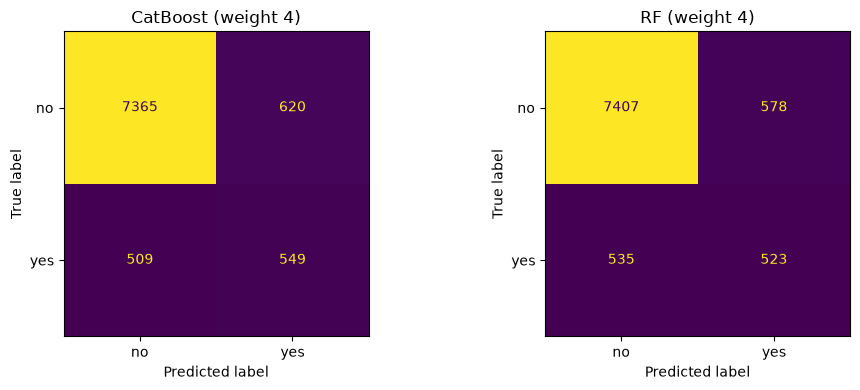

In [ ]:
RUN_TEST = True   # FINAL one-time test run. Chosen on validation (D1): CatBoost (weight 4); runner-up RF (weight 4)

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from catboost import CatBoostClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, roc_curve, ConfusionMatrixDisplay)

def ks_stat(y_true, prob):                      # Y. Dong (2024), Sec. 4.3
    fpr, tpr, _ = roc_curve(y_true, prob)
    return (tpr - fpr).max()

def cum_lift(y_true, prob, top):                # Y. Dong (2024), Sec. 4.4
    y_sorted = np.asarray(y_true)[np.argsort(-prob)]
    n_top = int(round(len(y_sorted) * top))
    return (y_sorted[:n_top].sum() / y_sorted.sum()) / top

# Retrain on train + validation (80% = same amount of data as round 1), then score the test set once
X_tv, y_tv = pd.concat([X_train, X_val]), pd.concat([y_train, y_val])
X_tv_enc = pd.concat([X_train_enc, X_val_enc])

final_models = {
    "CatBoost (weight 4)": CatBoostClassifier(class_weights=W4, **cb_settings),
    "RF (weight 4)":       RandomForestClassifier(n_estimators=200, min_samples_leaf=5, class_weight=W4,
                                                  n_jobs=-1, random_state=42),
}

rows, final_probs = {}, {}
for name, model in final_models.items():
    is_cb = name.startswith("CatBoost")
    X_fit, X_t = (to_cb(X_tv), to_cb(X_test)) if is_cb else (X_tv_enc, X_test_enc)
    model.fit(X_fit, y_tv)
    prob = model.predict_proba(X_t)[:, 1]
    pred = (prob >= 0.5).astype(int)
    final_probs[name] = prob
    rows[name] = {"Accuracy": accuracy_score(y_test, pred),
                  "Precision": precision_score(y_test, pred, zero_division=0),
                  "Recall": recall_score(y_test, pred),
                  "F1": f1_score(y_test, pred),
                  "ROC-AUC": roc_auc_score(y_test, prob),
                  "PR-AUC": average_precision_score(y_test, prob),
                  "KS": ks_stat(y_test, prob),
                  "Lift @ top 50%": cum_lift(y_test, prob, 0.50)}
    print(f"{name} done")

print(f"\nTest set ({len(y_test):,} rows). Majority-class accuracy (always 'no'): {(y_test == 0).mean():.3f}")
display(pd.DataFrame(rows).T.round(3))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, prob) in zip(axes, final_probs.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, (prob >= 0.5).astype(int),
                                            display_labels=["no", "yes"], ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout(); plt.show()

# 11. Round 3: 외부 경제 지표 (Extension, 최종 모델)
Eurostat 월별 지표 5개를 통화 월 기준으로 연결합니다. 통화 시점에 이미 발표된 값만 쓰도록 1개월 (실업률은 2개월) 시차를 둡니다.

### 경제 지표 내려받기와 연결

In [ ]:
import json, ssl, urllib.request, urllib.parse
import pandas as pd
import truststore

# Use Windows' own certificate check (same as your browser) -> fixes CERTIFICATE_VERIFY_FAILED
ssl_context = truststore.SSLContext(ssl.PROTOCOL_TLS_CLIENT)

def eurostat_monthly(dataset, **filters):
    """One monthly series from the Eurostat API (JSON-stat) -> pandas Series indexed by month."""
    params = {**filters, "sinceTimePeriod": "2007-01", "untilTimePeriod": "2010-12"}
    url = (f"https://ec.europa.eu/eurostat/api/dissemination/statistics/1.0/data/{dataset}?"
           + urllib.parse.urlencode(params))
    with urllib.request.urlopen(url, timeout=60, context=ssl_context) as response:
        js = json.load(response)
    time_index = js["dimension"]["time"]["category"]["index"]                 # {"2008-01": 0, ...}
    s = pd.Series({t: js["value"].get(str(i)) for t, i in time_index.items()}, dtype=float)
    s.index = pd.PeriodIndex([t.replace("M", "-") for t in s.index], freq="M")
    s = s.sort_index()
    return s.reindex(pd.period_range(s.index.min(), s.index.max(), freq="M"))  # no gaps -> shift works

# Public monthly indicators. lag = months back, so a call only "sees" values already published on its date
indicators = {
    "euribor3m":  (eurostat_monthly("irt_st_m", geo="EA", int_rt="IRT_M3"), 1),                         # 3-month interest rate, euro area (short-term)
    "cpi_yoy":    (eurostat_monthly("prc_hicp_manr", geo="PT", coicop="CP00", unit="RCH_A"), 1),         # inflation, Portugal (% vs a year earlier)
    "cons_conf":  (eurostat_monthly("ei_bsco_m", geo="PT", indic="BS-CSMCI", s_adj="SA", unit="BAL"), 1),  # consumer confidence, Portugal
    "unemp_rate": (eurostat_monthly("une_rt_m", geo="PT", s_adj="SA", age="TOTAL", unit="PC_ACT", sex="T"), 2),  # unemployment %, Portugal
    "pt_10y":     (eurostat_monthly("irt_lt_mcby_m", geo="PT", int_rt="MCBY"), 1),                       # 10-year government bond yield, Portugal (long-term)
}
monthly = pd.DataFrame({name: s.shift(lag) for name, (s, lag) in indicators.items()})

# One row per customer: call month -> indicator values (same row numbers as df, X_train, X_val, X_test)
call_month = dates.dt.to_period("M")                     # `dates` from the date-rebuild cell (Step 24-1)
macro = monthly.reindex(call_month.values).set_axis(df.index)

print("Indicator values used for each call month (already lagged):")
print(monthly.loc["2008-05":"2010-11"].round(2).to_string())
print("\nMissing values:", macro.isna().sum().to_dict())
print("\nSubscription rate by Euribor level (training rows only):")
print(y_train.groupby(pd.qcut(macro.loc[X_train.index, "euribor3m"], 4, duplicates="drop"), observed=True)
             .agg(rate="mean", rows="size").round(3))

Indicator values used for each call month (already lagged):
         euribor3m  cpi_yoy  cons_conf  unemp_rate  pt_10y
2008-05       4.78      2.5      -22.2         9.0    4.52
2008-06       4.86      2.8      -23.3         9.0    4.60
2008-07       4.94      3.4      -33.2         9.1    4.96
2008-08       4.96      3.1      -30.3         9.3    4.95
2008-09       4.97      3.1      -26.6         9.2    4.69
2008-10       5.02      3.2      -21.6         9.4    4.66
2008-11       5.11      2.5      -25.5         9.4    4.56
2008-12       4.24      1.4      -28.1         9.3    4.35
2009-01       3.29      0.8      -30.5         9.3    4.00
2009-02       2.46      0.1      -32.7         9.8    4.32
2009-03       1.94      0.1      -32.9        10.0    4.52
2009-04       1.64     -0.6      -30.7        10.2    4.68
2009-05       1.42     -0.5      -26.7        10.6    4.53
2009-06       1.28     -1.3      -25.9        10.8    4.29
2009-07       1.23     -1.6      -23.2        11.0    4

### 연결 결과 보기와 CSV 저장 (보기용, 모델은 이 파일을 읽지 않음)

In [ ]:
# Show how the economic data was attached: one row per customer (original file order). Nothing is changed.
merged_view = df[["age", "job", "day", "month", "y"]].copy()
merged_view["call_date"] = dates.dt.date                                # rebuilt date (date-rebuild cell)
merged_view["call_month"] = dates.dt.to_period("M").astype(str)          # the key used for the merge
merged_view = merged_view.join(macro[list(monthly.columns)])            # the 5 economic columns (already lagged)
merged_view["set"] = "train"                                            # which part of the split each row is in
merged_view.loc[X_val.index, "set"] = "validation"
merged_view.loc[X_test.index, "set"] = "test"

display(merged_view.head(5))                               # start of the file (May 2008)
display(merged_view.tail(5))                               # end of the file (Nov 2010)
display(merged_view.sample(8, random_state=1))             # random customers from different months

# Save a copy you can open in Excel (next to bank-full.csv). Only for viewing: the models don't read this file.
merged_view.to_csv(r"C:\personal_project_1\bank\bank_full_with_economic_data.csv", index_label="row")
print("Saved:", len(merged_view), "rows")

,age,job,day,month,y,call_date,call_month,euribor3m,cpi_yoy,cons_conf,unemp_rate,pt_10y,set
0,58,management,5,may,no,2008-05-05,2008-05,4.7835,2.5,-22.2,9.0,4.52,train
1,44,technician,5,may,no,2008-05-05,2008-05,4.7835,2.5,-22.2,9.0,4.52,train
2,33,entrepreneur,5,may,no,2008-05-05,2008-05,4.7835,2.5,-22.2,9.0,4.52,validation
3,47,blue-collar,5,may,no,2008-05-05,2008-05,4.7835,2.5,-22.2,9.0,4.52,validation
4,33,unknown,5,may,no,2008-05-05,2008-05,4.7835,2.5,-22.2,9.0,4.52,train


,age,job,day,month,y,call_date,call_month,euribor3m,cpi_yoy,cons_conf,unemp_rate,pt_10y,set
45206,51,technician,17,nov,yes,2010-11-17,2010-11,0.99767,2.3,-37.7,12.8,6.05,train
45207,71,retired,17,nov,yes,2010-11-17,2010-11,0.99767,2.3,-37.7,12.8,6.05,validation
45208,72,retired,17,nov,yes,2010-11-17,2010-11,0.99767,2.3,-37.7,12.8,6.05,train
45209,57,blue-collar,17,nov,no,2010-11-17,2010-11,0.99767,2.3,-37.7,12.8,6.05,validation
45210,37,entrepreneur,17,nov,no,2010-11-17,2010-11,0.99767,2.3,-37.7,12.8,6.05,train


,age,job,day,month,y,call_date,call_month,euribor3m,cpi_yoy,cons_conf,unemp_rate,pt_10y,set
3610,42,blue-collar,15,may,no,2008-05-15,2008-05,4.78350,2.5,-22.2,9.0,4.52,train
11677,37,technician,20,jun,no,2008-06-20,2008-06,4.85738,2.8,-23.3,9.0,4.60,train
33018,32,admin.,17,apr,no,2009-04-17,2009-04,1.63545,-0.6,-30.7,10.2,4.68,train
44323,53,blue-collar,28,jul,yes,2010-07-28,2010-07,0.72759,1.1,-26.9,12.7,5.54,train
8119,32,technician,2,jun,no,2008-06-02,2008-06,4.85738,2.8,-23.3,9.0,4.60,train
38958,28,admin.,18,may,no,2009-05-18,2009-05,1.42230,-0.5,-26.7,10.6,4.53,test
18496,41,unemployed,31,jul,no,2008-07-31,2008-07,4.94052,3.4,-33.2,9.1,4.96,train
4249,36,admin.,19,may,no,2008-05-19,2008-05,4.78350,2.5,-22.2,9.0,4.52,train


Saved: 45211 rows


### ① 무작위 분할 validation과 ③ 시간 순서 (2008–09 → 2010), 경제 지표 있음 / 없음

In [ ]:
import pandas as pd
from catboost import CatBoostClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, roc_auc_score, average_precision_score

macro_cols = list(monthly.columns)                  # the 5 indicators from cell 1 (incl. pt_10y)
X_all = pd.concat([X_train, X_val])                 # train + validation (test set not used)
X_all_enc = pd.concat([X_train_enc, X_val_enc])
y_all = pd.concat([y_train, y_val])

def fit_score(kind, use_macro, tr, ev):
    """Train on rows `tr`, score rows `ev` (cutoff 0.5). Same settings as the final models (w = 4)."""
    if kind == "CatBoost":
        X_tr, X_ev = to_cb(X_all.loc[tr]), to_cb(X_all.loc[ev])
        model = CatBoostClassifier(class_weights=W4, **cb_settings)
    else:
        X_tr, X_ev = X_all_enc.loc[tr], X_all_enc.loc[ev]
        model = RandomForestClassifier(n_estimators=200, min_samples_leaf=5, class_weight=W4,
                                       n_jobs=-1, random_state=42)
    if use_macro:                                     # add the indicator columns
        X_tr, X_ev = X_tr.join(macro.loc[tr, macro_cols]), X_ev.join(macro.loc[ev, macro_cols])
    prob = model.fit(X_tr, y_all.loc[tr]).predict_proba(X_ev)[:, 1]
    y_ev = y_all.loc[ev]
    return {"rows scored": len(ev), "yes rate": y_ev.mean(),
            "F1": f1_score(y_ev, (prob >= 0.5).astype(int)),
            "ROC-AUC": roc_auc_score(y_ev, prob), "PR-AUC": average_precision_score(y_ev, prob)}

# Check 1: the usual split (train 60% -> validation 20%)
# Check 2: time order (train+val rows from 2008-2009 -> train+val rows from 2010) = "predict the future"
in_2010 = (dates.loc[X_all.index].dt.year == 2010).values
checks = {"1. Validation (random split)":   (X_train.index, X_val.index),
          "2. Time order (2008-09 -> 2010)": (X_all.index[~in_2010], X_all.index[in_2010])}

rows = []
for check, (tr, ev) in checks.items():
    for kind in ["CatBoost", "Random Forest"]:
        for use_macro in [False, True]:
            rows.append({"Check": check, "Model": f"{kind} (w = 4)", "Macro": "yes" if use_macro else "no",
                         **fit_score(kind, use_macro, tr, ev)})
            print(f"{check} / {kind} / macro {'yes' if use_macro else 'no'} done")

macro_table = pd.DataFrame(rows).set_index(["Check", "Model", "Macro"]).round(3)
print("\nTest set not used.")
macro_table

1. Validation (random split) / CatBoost / macro no done
1. Validation (random split) / CatBoost / macro yes done
1. Validation (random split) / Random Forest / macro no done
1. Validation (random split) / Random Forest / macro yes done
2. Time order (2008-09 -> 2010) / CatBoost / macro no done
2. Time order (2008-09 -> 2010) / CatBoost / macro yes done
2. Time order (2008-09 -> 2010) / Random Forest / macro no done
2. Time order (2008-09 -> 2010) / Random Forest / macro yes done

Test set not used.


rows scored  \
Check                           Model                 Macro                
1. Validation (random split)    CatBoost (w = 4)      no            9042   
                                                      yes           9042   
                                Random Forest (w = 4) no            9042   
                                                      yes           9042   
2. Time order (2008-09 -> 2010) CatBoost (w = 4)      no            2064   
                                                      yes           2064   
                                Random Forest (w = 4) no            2064   
                                                      yes           2064   

                                                             yes rate     F1  \
Check                           Model                 Macro                    
1. Validation (random split)    CatBoost (w = 4)      no        0.117  0.506   
                                                      yes       0.117  0.526   
                                Random Forest (w = 4) no        0.117  0.490   
                                                      yes       0.117  0.522   
2. Time order (2008-09 -> 2010) CatBoost (w = 4)      no        0.514  0.641   
                                                      yes       0.514  0.670   
                                Random Forest (w = 4) no        0.514  0.646   
                                                      yes       0.514  0.662   

                                                             ROC-AUC  PR-AUC  
Check                           Model                 Macro                   
1. Validation (random split)    CatBoost (w = 4)      no       0.811   0.468  
                                                      yes      0.820   0.490  
                                Random Forest (w = 4) no       0.800   0.469  
                                                      yes      0.815   0.487  
2. Time order (2008-09 -> 2010) CatBoost (w = 4)      no       0.635   0.653  
                                                      yes      0.655   0.665  
                                Random Forest (w = 4) no       0.665   0.670  
                                                      yes      0.642   0.652

### ① 진단: 경제 지표 대신 월 번호만 넣으면?

In [ ]:
import pandas as pd

# Diagnostic: is the validation gain "economics" or just "which month is this"?
# Replace the 5 indicators with ONE column that only says which month the call was in (no economic meaning).
macro["month_id"] = (dates.dt.year - 2008) * 12 + dates.dt.month    # May 2008 = 5, ..., Nov 2010 = 35
saved_cols, macro_cols = macro_cols, ["month_id"]

tr, ev = checks["1. Validation (random split)"]                    # same train / validation rows as before
rows = []
for kind in ["CatBoost", "Random Forest"]:
    rows.append({"Model": f"{kind} (w = 4)", "Extra columns": "month ID only", **fit_score(kind, True, tr, ev)})
    print(f"{kind} done")

macro_cols = saved_cols                                             # put things back as they were
macro = macro.drop(columns="month_id")

print("\nCompare with macro_table, check 1 (no: CatBoost 0.506 / RF 0.490; 5 indicators: 0.526 / 0.522). Test set not used.")
pd.DataFrame(rows).set_index(["Model", "Extra columns"]).round(3)

CatBoost done
Random Forest done

Compare with macro_table, check 1 (no: CatBoost 0.506 / RF 0.490; 5 indicators: 0.526 / 0.522). Test set not used.


,,rows scored,yes rate,F1,ROC-AUC,PR-AUC
Model,Extra columns,,,,,
CatBoost (w = 4),month ID only,9042,0.117,0.523,0.820,0.494
Random Forest (w = 4),month ID only,9042,0.117,0.515,0.812,0.490


### ② 무작위 5-fold vs 월 단위 분리 5-fold (처음 보는 월만 평가)

In [ ]:
import time
import numpy as np, pandas as pd
from sklearn.model_selection import StratifiedKFold, GroupKFold
from catboost import CatBoostClassifier
from sklearn.metrics import f1_score, roc_auc_score, average_precision_score

# Memorization or real economic signal?
# Same rows (train + validation; test set not used), same CatBoost (w = 4). Only two things change:
#   1) the split:  random folds (validation months also appear in training)
#                  vs month-held-out folds (validation months are NEVER seen in training -> nothing to memorize)
#   2) the extra columns:  none / month ID only (no economic meaning) / the 5 economic indicators
X_all, y_all = pd.concat([X_train, X_val]), pd.concat([y_train, y_val])
X_cb = to_cb(X_all)
call_month = dates.loc[X_all.index].dt.to_period("M").astype(str).values      # group label for each row

extras = macro[list(monthly.columns)].assign(month_id=(dates.dt.year - 2008) * 12 + dates.dt.month)
extra_sets = {"none": [], "month ID only": ["month_id"], "5 indicators": list(monthly.columns)}

splits = {
    "Random folds (months shared)": list(StratifiedKFold(5, shuffle=True, random_state=42).split(X_cb, y_all)),
    "Month-held-out folds":         list(GroupKFold(5).split(X_cb, y_all, groups=call_month)),
}

rows = []
for split_name, folds in splits.items():
    for extra_name, cols in extra_sets.items():
        start = time.time()
        X_use = X_cb.join(extras.loc[X_all.index, cols]) if cols else X_cb
        oof = np.zeros(len(y_all))                                       # each row predicted by a model that never saw it
        for tr, ev in folds:
            model = CatBoostClassifier(class_weights=W4, **cb_settings).fit(X_use.iloc[tr], y_all.iloc[tr])
            oof[ev] = model.predict_proba(X_use.iloc[ev])[:, 1]
        rows.append({"Split": split_name, "Extra columns": extra_name,
                     "F1": f1_score(y_all, (oof >= 0.5).astype(int)),
                     "ROC-AUC": roc_auc_score(y_all, oof),
                     "PR-AUC": average_precision_score(y_all, oof)})
        print(f"{split_name} / {extra_name} done ({time.time() - start:.0f} s)")

print(f"\n{len(y_all):,} rows (train + validation). Test set not used.")
pd.DataFrame(rows).set_index(["Split", "Extra columns"]).round(3)

Random folds (months shared) / none done (303 s)
Random folds (months shared) / month ID only done (309 s)
Random folds (months shared) / 5 indicators done (288 s)
Month-held-out folds / none done (311 s)
Month-held-out folds / month ID only done (313 s)
Month-held-out folds / 5 indicators done (323 s)

36,168 rows (train + validation). Test set not used.


F1  ROC-AUC  PR-AUC
Split                        Extra columns                        
Random folds (months shared) none           0.489    0.801   0.445
                             month ID only  0.515    0.812   0.470
                             5 indicators   0.518    0.814   0.474
Month-held-out folds         none           0.226    0.638   0.274
                             month ID only  0.270    0.708   0.345
                             5 indicators   0.289    0.735   0.367

### Round 3 테스트 (최종 모델): 경제 지표 있음 / 없음, train + validation (80%)으로 다시 학습
첫 행은 Round 2 테스트와 같아야 합니다 (F1 0.493, ROC-AUC 0.806).

In [ ]:
RUN_TEST = True   # Round 3: ONE labelled test run, "Dong-style" (random split, economic indicators as normal columns)

import numpy as np, pandas as pd
from catboost import CatBoostClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, roc_curve, confusion_matrix)

def ks_stat(y_true, prob):                      # Y. Dong (2024), Sec. 4.3
    fpr, tpr, _ = roc_curve(y_true, prob)
    return (tpr - fpr).max()

def cum_lift(y_true, prob, top):                # Y. Dong (2024), Sec. 4.4
    y_sorted = np.asarray(y_true)[np.argsort(-prob)]
    n_top = int(round(len(y_sorted) * top))
    return (y_sorted[:n_top].sum() / y_sorted.sum()) / top

macro_cols = list(monthly.columns)              # the 5 indicators from cell 1

# Same as E1: retrain on train + validation (80%), score the test set once, cutoff 0.5
X_tv, y_tv = pd.concat([X_train, X_val]), pd.concat([y_train, y_val])

rows = {}
for use_macro in [False, True]:
    X_fit, X_t = to_cb(X_tv), to_cb(X_test)
    if use_macro:                                # add the 5 indicator columns (matched by row number)
        X_fit = X_fit.join(macro.loc[X_tv.index, macro_cols])
        X_t = X_t.join(macro.loc[X_test.index, macro_cols])
    prob = CatBoostClassifier(class_weights=W4, **cb_settings).fit(X_fit, y_tv).predict_proba(X_t)[:, 1]
    pred = (prob >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    name = "CatBoost (w4) + economic data" if use_macro else "CatBoost (w4) = E1 (check)"
    rows[name] = {"Accuracy": accuracy_score(y_test, pred),
                  "Precision": precision_score(y_test, pred, zero_division=0),
                  "Recall": recall_score(y_test, pred),
                  "F1": f1_score(y_test, pred),
                  "ROC-AUC": roc_auc_score(y_test, prob),
                  "PR-AUC": average_precision_score(y_test, prob),
                  "KS": ks_stat(y_test, prob),
                  "Lift @ top 50%": cum_lift(y_test, prob, 0.50),
                  "TP": tp, "FP": fp, "FN": fn}
    print(f"{name} done")

print(f"\nTest set ({len(y_test):,} rows). First row should repeat E1 (F1 0.493, ROC-AUC 0.806).")
pd.DataFrame(rows).T.round(3)

CatBoost (w4) = E1 (check) done
CatBoost (w4) + economic data done

Test set (9,043 rows). First row should repeat E1 (F1 0.493, ROC-AUC 0.806).


,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,KS,Lift @ top 50%,TP,FP,FN
CatBoost (w4) = E1 (check),0.875,0.470,0.519,0.493,0.806,0.463,0.490,1.662,549.0,620.0,509.0
CatBoost (w4) + economic data,0.874,0.469,0.596,0.525,0.818,0.492,0.524,1.690,631.0,714.0,427.0
